In [1]:
import pandas as pd

df = pd.read_csv('../data/dataset.csv')

In [2]:
# _____________________<( Columns )>___________________________
df_columns = df.columns
print(df_columns)
# ['Unnamed: 0', 'Pregnancies', 'Glucose', 'BloodPressure','SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Index(['Unnamed: 0', 'Pregnancies', 'Glucose', 'BloodPressure',
       'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')


In [3]:
# _____________________<( DF Shape )>__________________________
print(df.shape) #(768, 9)

(768, 9)


In [4]:
# _____________________<( exemple de data )>___________________
print(df.head(3))
#    Unnamed: 0  Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age
# 0           0            6      148             72             35        0  33.6                     0.627   50
# 1           1            1       85             66             29        0  26.6                     0.351   31
# 2           2            8      183             64              0        0  23.3                     0.672   32


   Unnamed: 0  Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  \
0           0            6      148             72             35        0   
1           1            1       85             66             29        0   
2           2            8      183             64              0        0   

    BMI  DiabetesPedigreeFunction  Age  
0  33.6                     0.627   50  
1  26.6                     0.351   31  
2  23.3                     0.672   32  


In [5]:
# _____________________<( identifier les doublons )>___________________
dupl_sum = df.duplicated().sum()
print(f'nombre des doubons : {dupl_sum}')
# nombre des doubons : 0


nombre des doubons : 0


In [6]:
# _____________________<( identifier null values )>___________________
null_values = df.isna().sum()
print(f'null values in each column : {null_values}')


null values in each column : Unnamed: 0                  0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [7]:
# _____________________<( columns data type )>___________________
column_type = df.dtypes
print(f'columns types : {column_type}')


columns types : Unnamed: 0                    int64
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
dtype: object


In [8]:
# _____________________<( drop the index column )>___________________
df = df.drop(columns=['Unnamed: 0'])

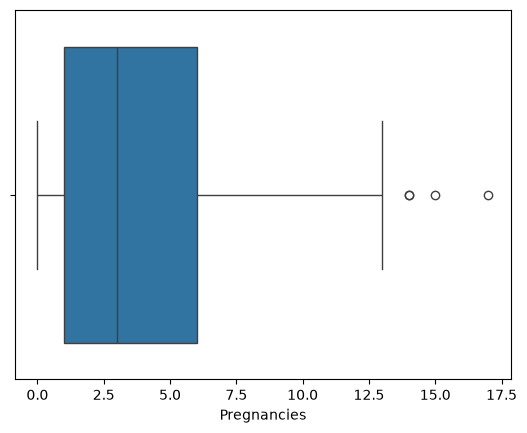

In [9]:
# _____________________<( search for outliers )>___________________
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Pregnancies'])
plt.show()

# note : no outliers here

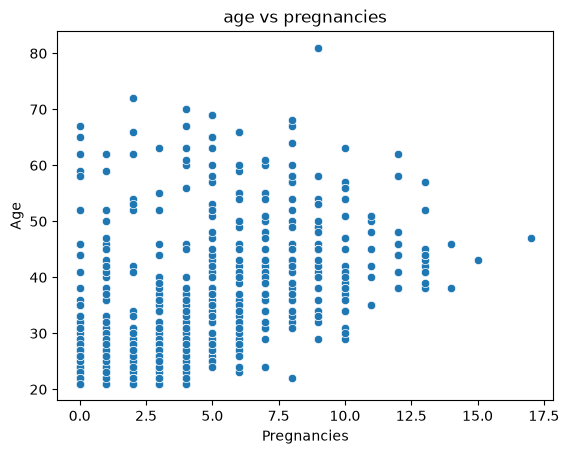

In [10]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Pregnancies'], y=df['Age'])
plt.xlabel('Pregnancies')
plt.ylabel('Age')
plt.title('age vs pregnancies')
plt.show()

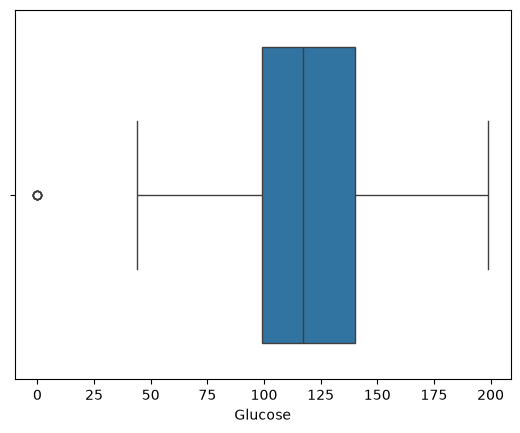

In [11]:
# _____________________<( search for outliers )>___________________
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Glucose'])
plt.show()

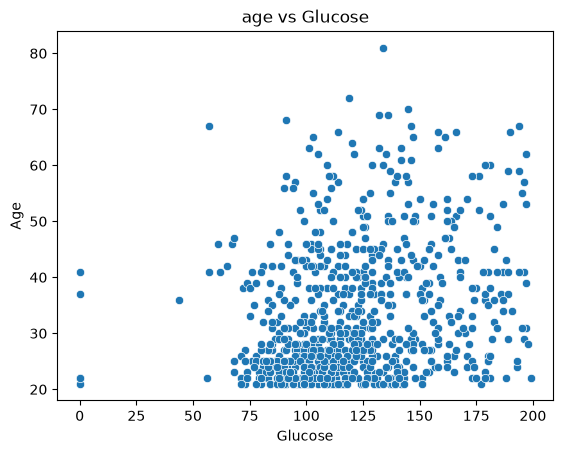

In [12]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Glucose'], y=df['Age'])
plt.xlabel('Glucose')
plt.ylabel('Age')
plt.title('age vs Glucose')
plt.show()

## replacing the invalide 0 values using KNN

In [13]:
from sklearn.impute import KNNImputer
import numpy as np

features_0 = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction']
features = df.columns
imputer = KNNImputer(n_neighbors=5)
for col in features_0 :
    df.loc[df[col] == 0, col] = np.nan
df[features] = imputer.fit_transform(df[features])


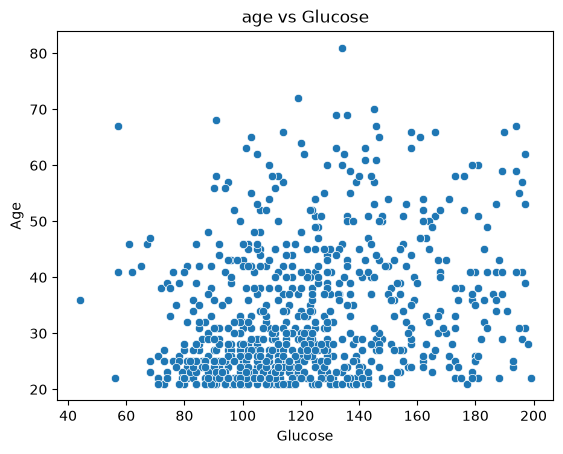

In [14]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Glucose'], y=df['Age'])
plt.xlabel('Glucose')
plt.ylabel('Age')
plt.title('age vs Glucose')
plt.show()

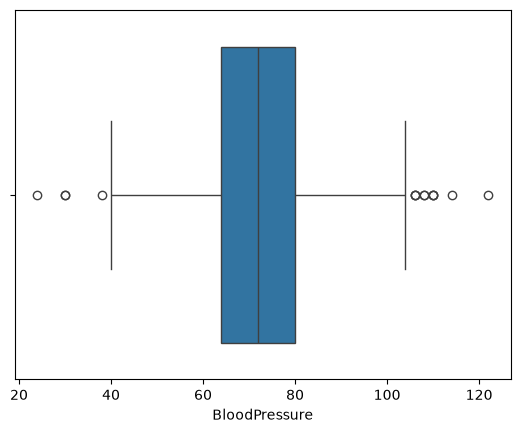

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['BloodPressure'])
plt.show()

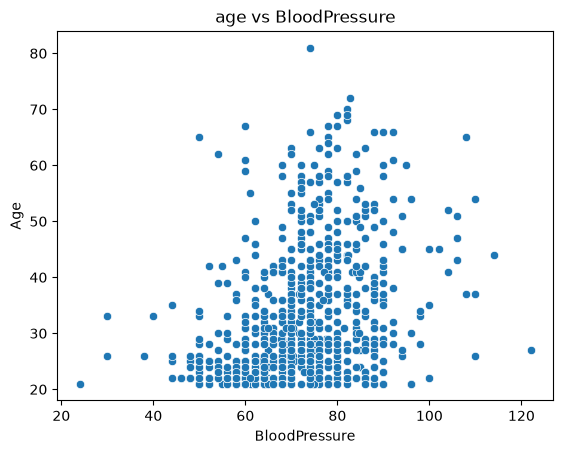

In [16]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BloodPressure'], y=df['Age'])
plt.xlabel('BloodPressure')
plt.ylabel('Age')
plt.title('age vs BloodPressure')
plt.show()

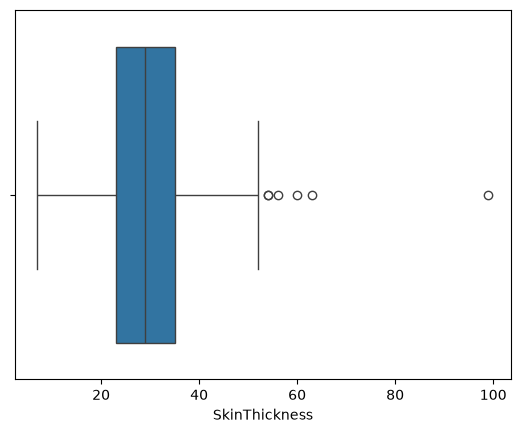

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['SkinThickness'])
plt.show()

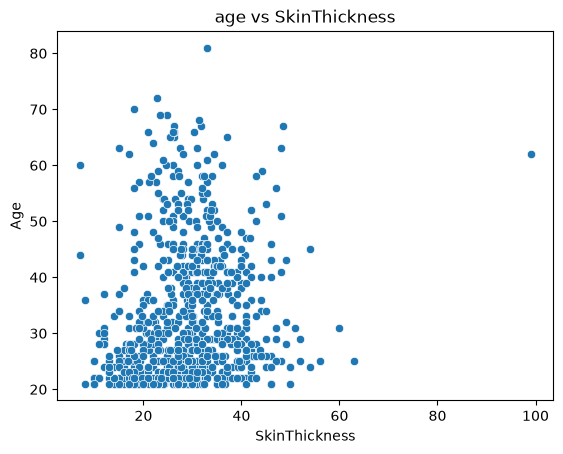

In [18]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['SkinThickness'], y=df['Age'])
plt.xlabel('SkinThickness')
plt.ylabel('Age')
plt.title('age vs SkinThickness')
plt.show()

In [19]:
upper_bound = df["SkinThickness"].quantile(0.995)

df["SkinThickness"] = df["SkinThickness"].clip(upper=upper_bound)

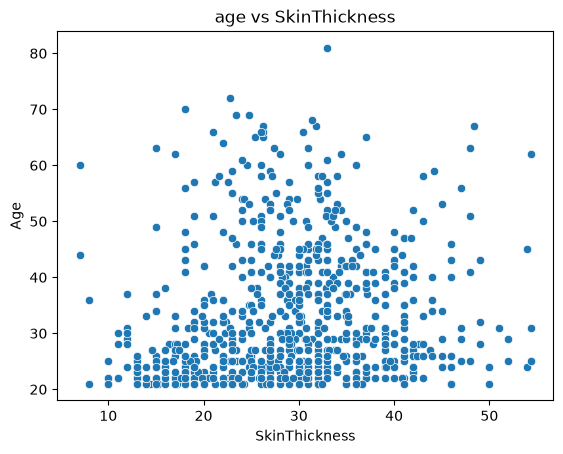

In [20]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['SkinThickness'], y=df['Age'])
plt.xlabel('SkinThickness')
plt.ylabel('Age')
plt.title('age vs SkinThickness')
plt.show()

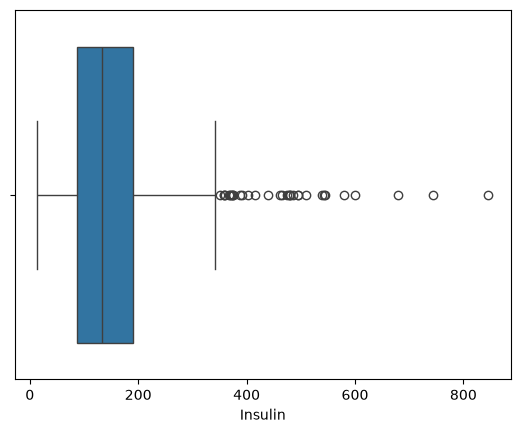

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Insulin'])
plt.show()



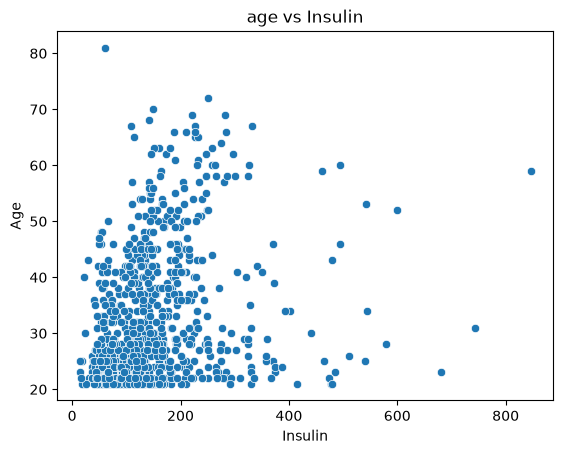

In [22]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Insulin'], y=df['Age'])
plt.xlabel('Insulin')
plt.ylabel('Age')
plt.title('age vs Insulin')
plt.show()

In [23]:
print(df[df['Insulin'] > 600])

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
13           1.0    189.0           60.0           23.0    846.0  30.1   
228          4.0    197.0           70.0           39.0    744.0  36.7   
247          0.0    165.0           90.0           33.0    680.0  52.3   

     DiabetesPedigreeFunction   Age  
13                      0.398  59.0  
228                     2.329  31.0  
247                     0.427  23.0  


In [24]:
print(f'rows with insulin = 0 : {(df["Insulin"] == 0).sum()}')

rows with insulin = 0 : 0


In [25]:
upper_bound = df["Insulin"].quantile(0.996)

df["Insulin"] = df["Insulin"].clip(upper=upper_bound)

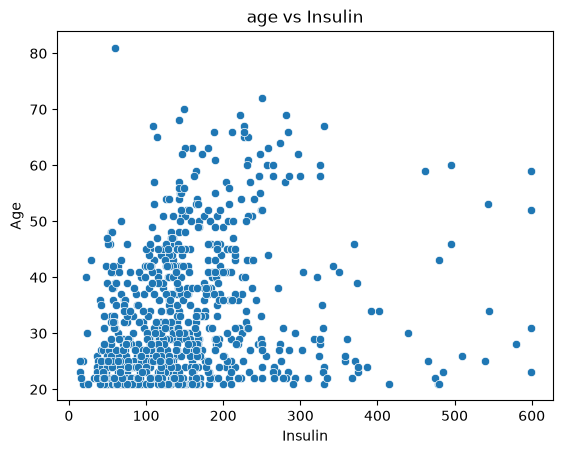

In [26]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Insulin'], y=df['Age'])
plt.xlabel('Insulin')
plt.ylabel('Age')
plt.title('age vs Insulin')
plt.show()

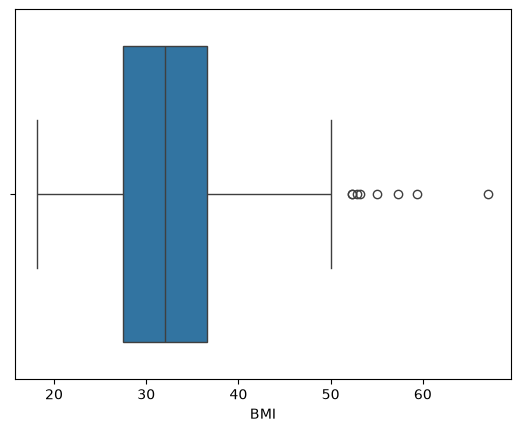

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['BMI'])
plt.show()

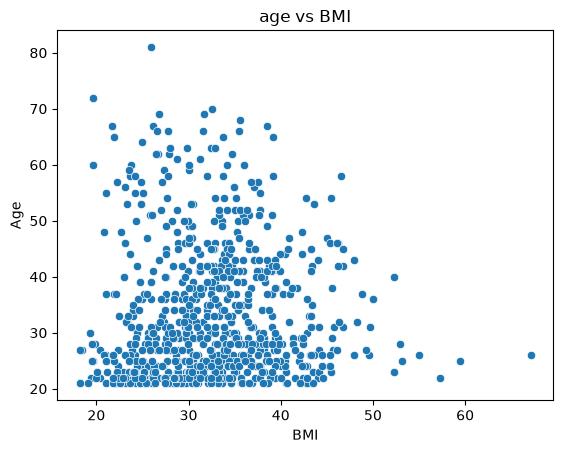

In [28]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BMI'], y=df['Age'])
plt.xlabel('BMI')
plt.ylabel('Age')
plt.title('age vs BMI')
plt.show()

In [29]:
upper_bound = df["BMI"].quantile(0.995)

df["BMI"] = df["BMI"].clip(upper=upper_bound)

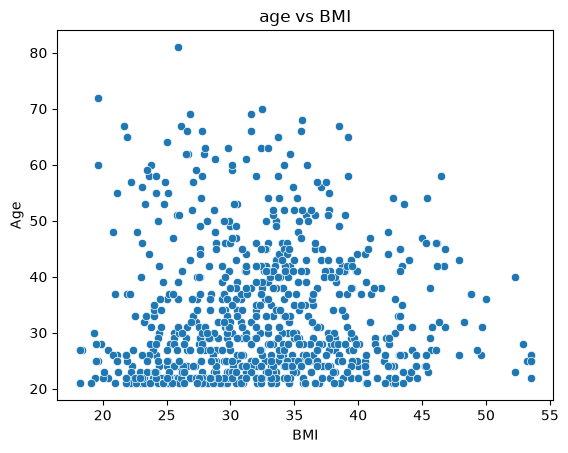

In [30]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BMI'], y=df['Age'])
plt.xlabel('BMI')
plt.ylabel('Age')
plt.title('age vs BMI')
plt.show()

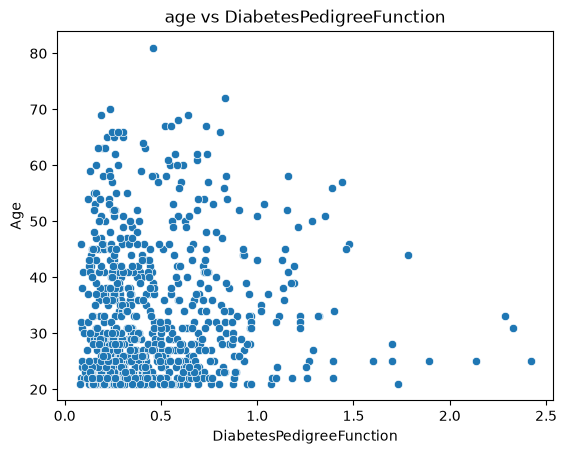

In [31]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['DiabetesPedigreeFunction'], y=df['Age'])
plt.xlabel('DiabetesPedigreeFunction')
plt.ylabel('Age')
plt.title('age vs DiabetesPedigreeFunction')
plt.show()

In [32]:
print(df[df['DiabetesPedigreeFunction'] > 2.0])

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
4            0.0    137.0           40.0          35.00  168.000  43.100   
228          4.0    197.0           70.0          39.00  598.572  36.700   
370          3.0    173.0           82.0          48.00  465.000  38.400   
445          0.0    180.0           78.0          54.33   14.000  53.497   

     DiabetesPedigreeFunction   Age  
4                       2.288  33.0  
228                     2.329  31.0  
370                     2.137  25.0  
445                     2.420  25.0  


In [33]:
for col in df.columns:
    print(f"Max de {col} : {df[col].max()}")
    print(f"Min de {col} : {df[col].min()}")
    print()

Max de Pregnancies : 17.0
Min de Pregnancies : 0.0

Max de Glucose : 199.0
Min de Glucose : 44.0

Max de BloodPressure : 122.0
Min de BloodPressure : 24.0

Max de SkinThickness : 54.32999999999993
Min de SkinThickness : 7.0

Max de Insulin : 598.5720000000003
Min de Insulin : 14.0

Max de BMI : 53.496999999999936
Min de BMI : 18.2

Max de DiabetesPedigreeFunction : 2.42
Min de DiabetesPedigreeFunction : 0.078

Max de Age : 81.0
Min de Age : 21.0



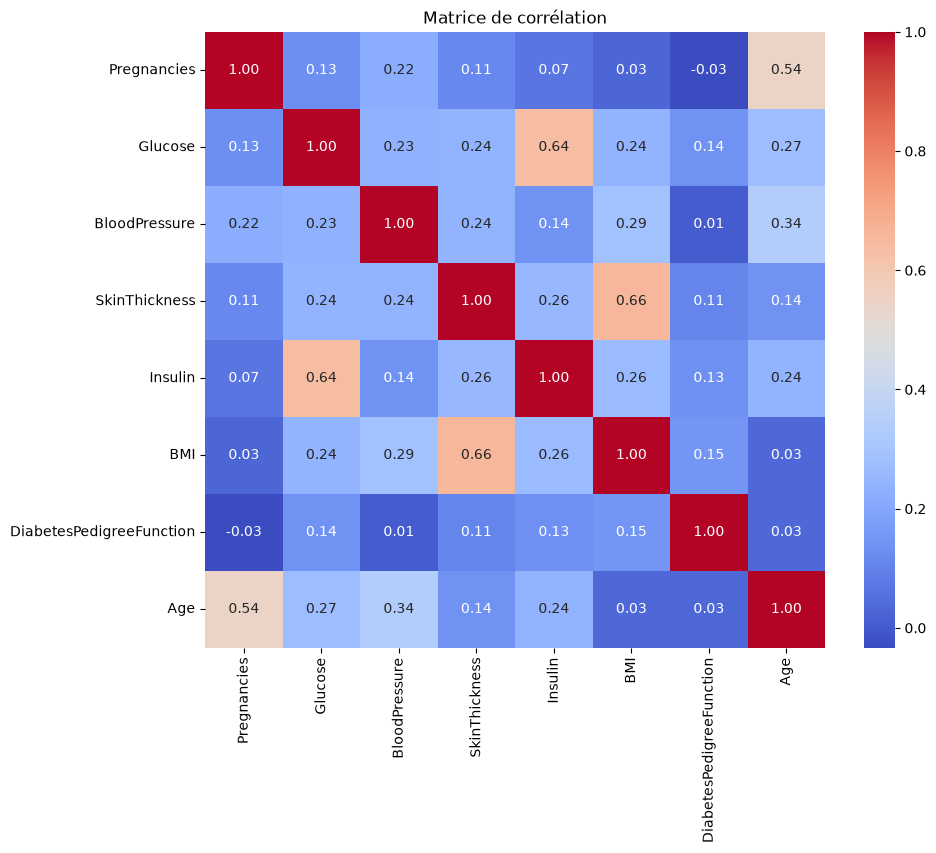

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

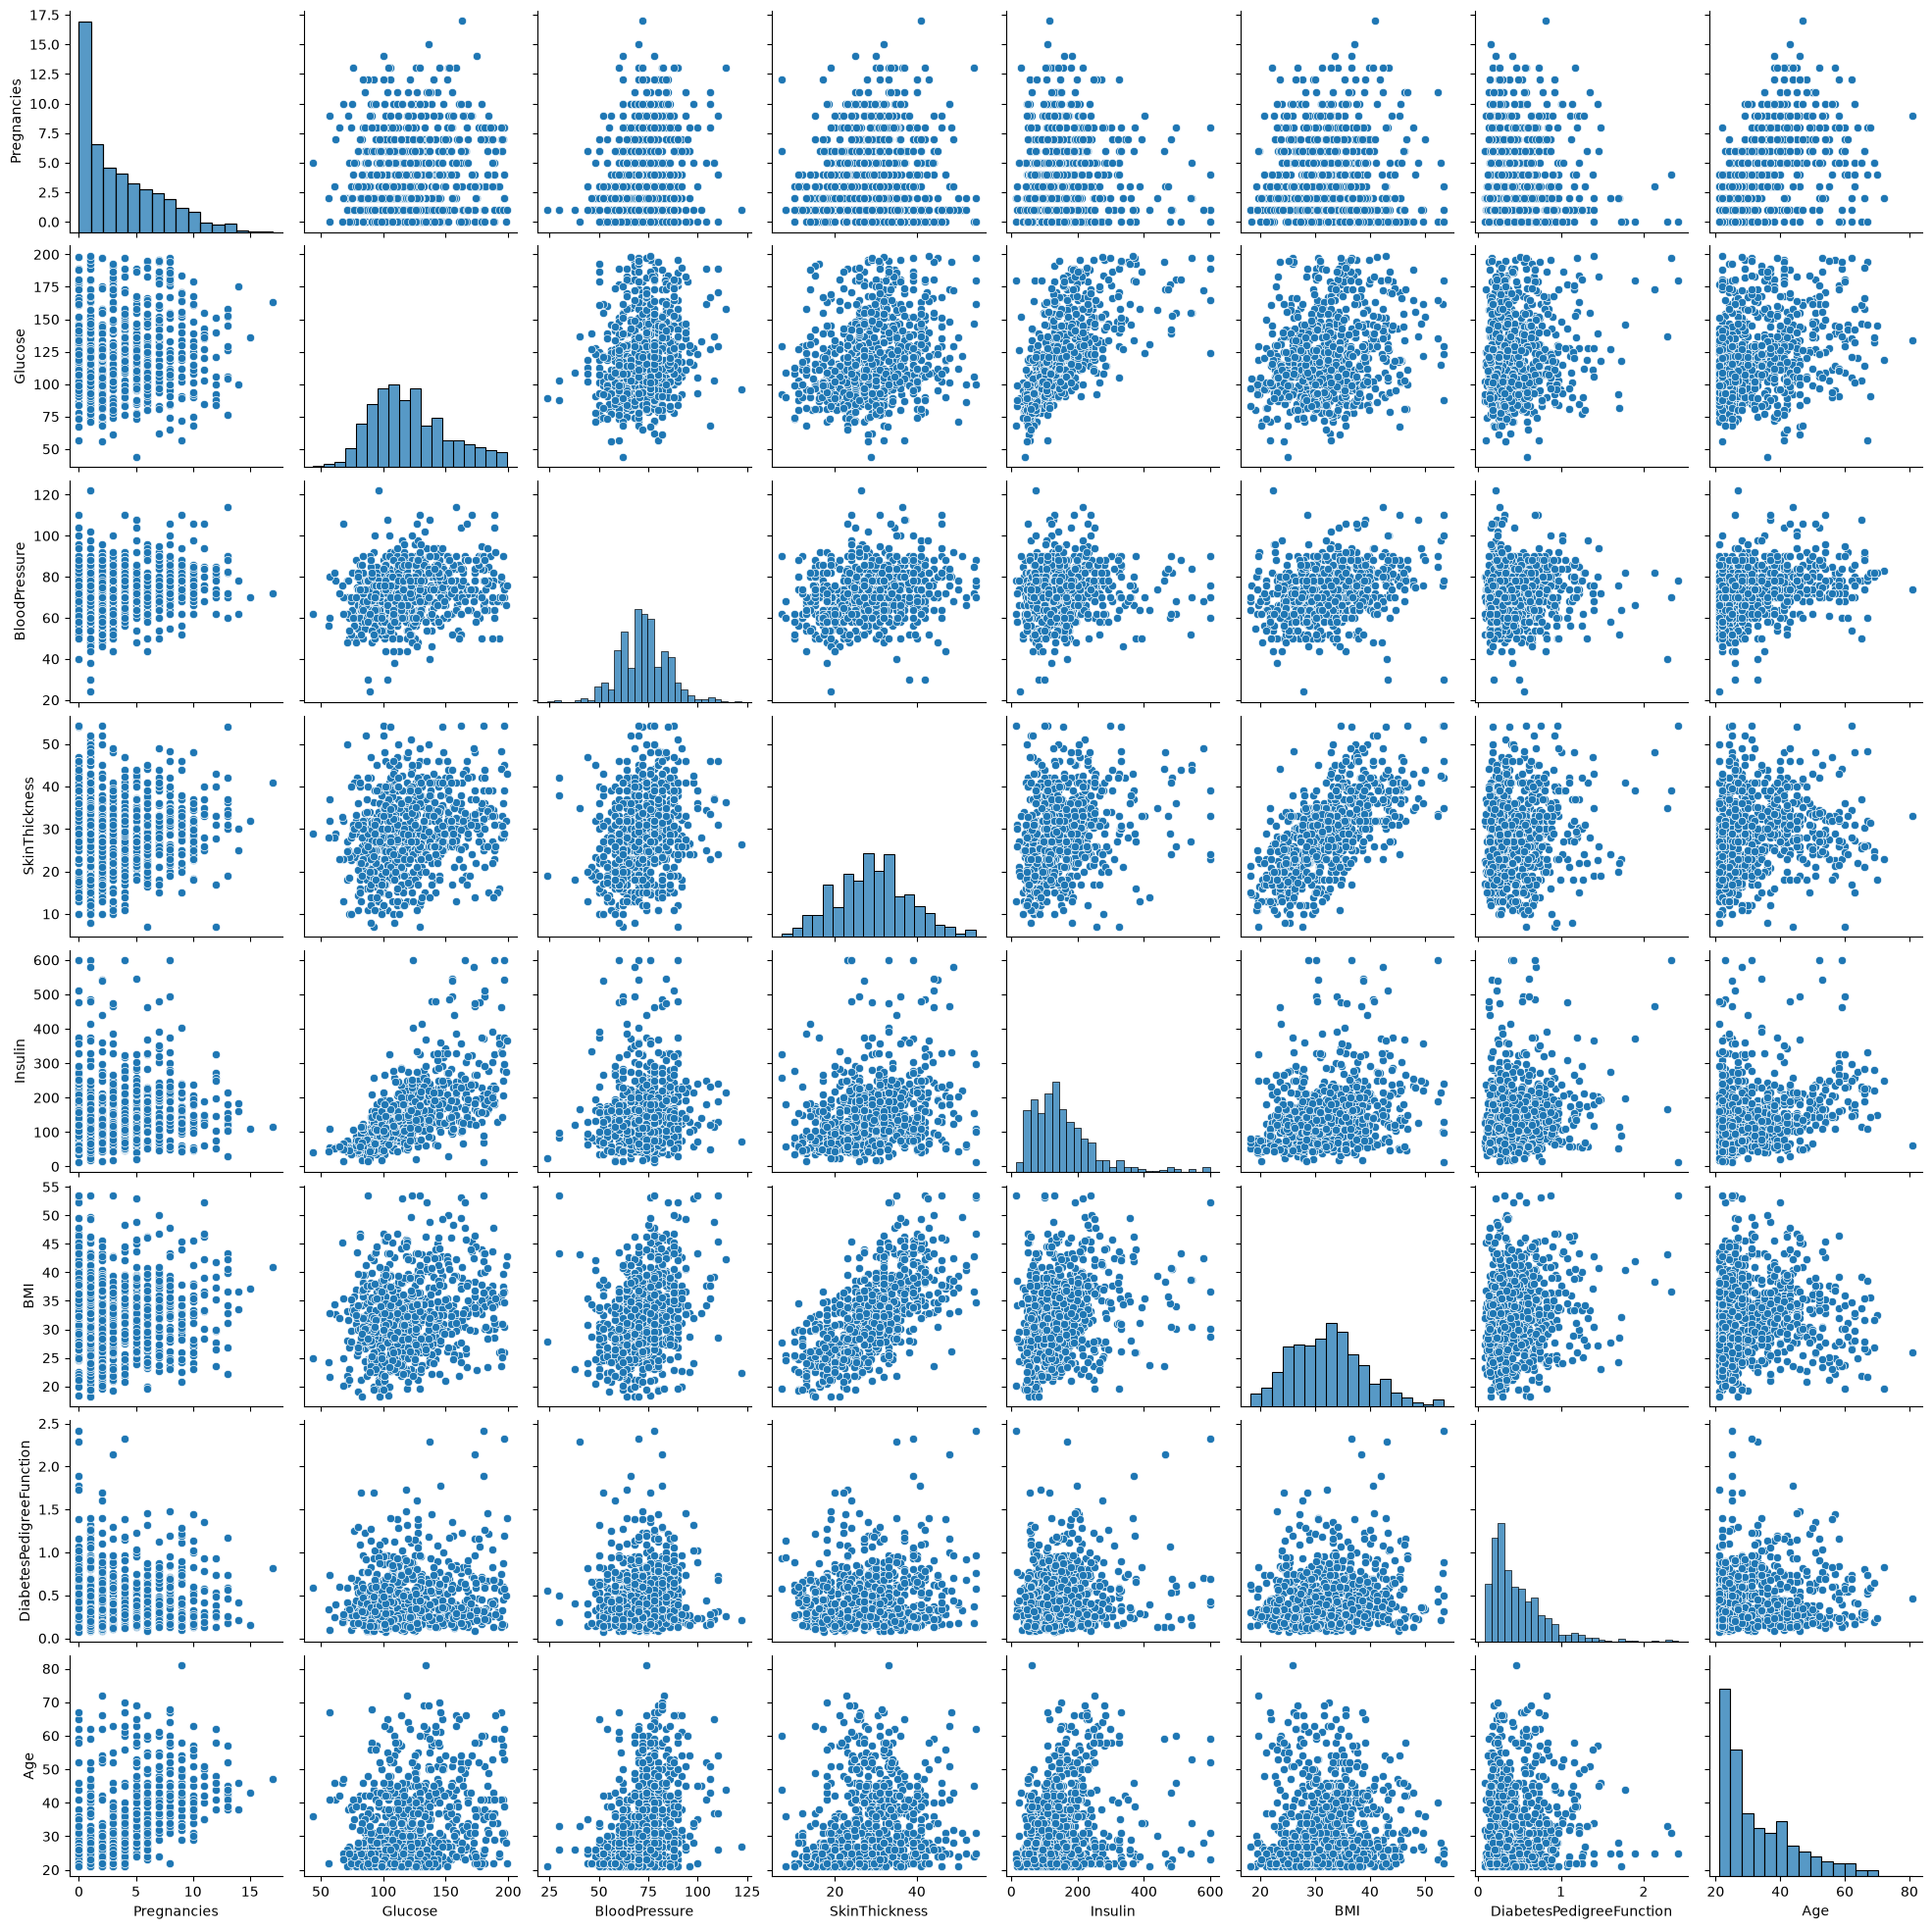

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
# numeric_cols = [
#     'Pregnancies', 
#     'Glucose', 
#     'BloodPressure',
#     'SkinThickness', 
#     'Insulin', 
#     'BMI', 
#     'DiabetesPedigreeFunction', 
#     'Age']

features = df.columns
sns.pairplot(df[features])
plt.show()


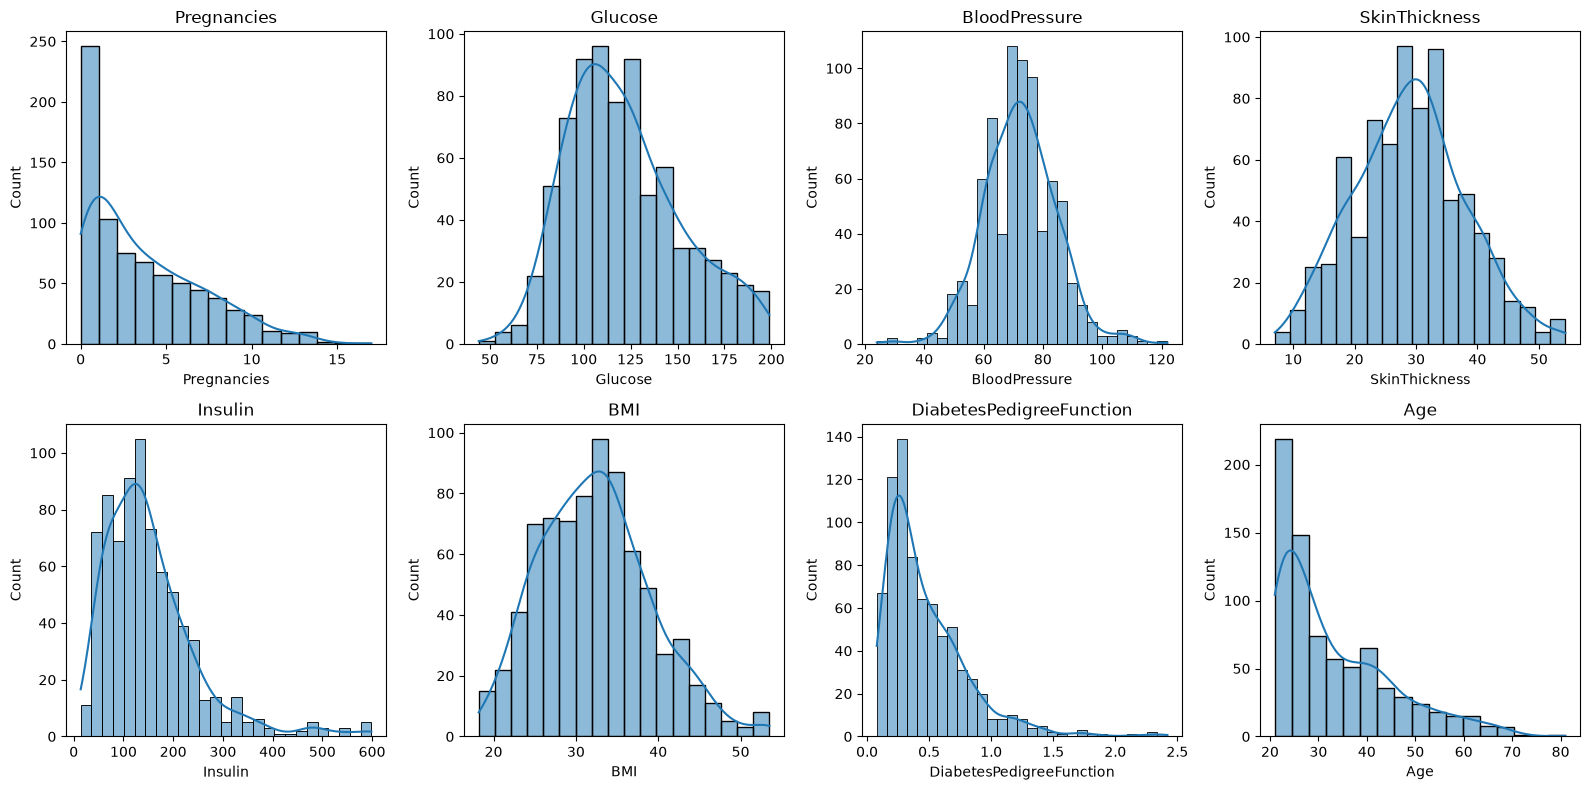

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()

In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[features] = scaler.fit_transform(df[features])

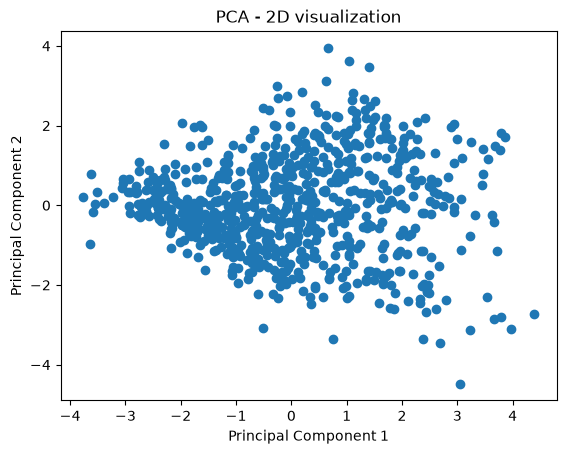

In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df[features])

import matplotlib.pyplot as plt

plt.scatter(X_pca[:, 0], X_pca[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D visualization")

plt.show()

In [39]:
# from sklearn.cluster import KMeans
# import matplotlib.pyplot as plt
# from sklearn.metrics import silhouette_score


# inertias = []
# silhouette_scores = []


# for k in range(2, 7):
#     kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
#     # kmeans.fit(df[numeric_cols])
#     labels = kmeans.fit_predict(df[numeric_cols])
    
#     inertias.append(kmeans.inertia_)
#     score = silhouette_score(df[numeric_cols], labels)
#     silhouette_scores.append(score)

# print(silhouette_scores)
# print(len(silhouette_scores))


# # elbow
# plt.plot(range(2, 7), inertias, marker='o')
# plt.xlabel("Nombre de clusters (K)")
# plt.ylabel("Inertie")
# plt.title("Méthode du coude")
# plt.show()

# # silouhaitte
# plt.plot(range(2, 7), silhouette_scores, marker='o')
# plt.xlabel("K")
# plt.ylabel("Silhouette Score")
# plt.title("Silhouette Method")

# plt.show()

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = {}

for k in [2, 3]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(df[features])

    inertia = kmeans.inertia_
    silhouette = silhouette_score(df[features], labels)

    results[k] = {
        "model": kmeans,
        "labels": labels,
        "inertia": inertia,
        "silhouette": silhouette
    }

    print(f"K = {k}")
    print(f"Inertia: {inertia:.2f}")
    print(f"Silhouette Score: {silhouette:.3f}")

K = 2
Inertia: 4802.60
Silhouette Score: 0.214
K = 3
Inertia: 4165.26
Silhouette Score: 0.203


In [41]:
print(df.head(4))

   Pregnancies   Glucose  BloodPressure  SkinThickness   Insulin       BMI  \
0     0.639947  0.866296      -0.031424       0.660012  0.174759  0.178636   
1    -0.844885 -1.200858      -0.523271      -0.002808 -0.990479 -0.857035   
2     1.233880  2.014715      -0.687220      -0.356312  0.128318 -1.345279   
3    -0.844885 -1.069610      -0.523271      -0.665628 -0.616843 -0.635105   

   DiabetesPedigreeFunction       Age  
0                  0.468492  1.425995  
1                 -0.365061 -0.190672  
2                  0.604397 -0.105584  
3                 -0.920763 -1.041549  


| Column                       | What it measures                                             | Typical unit / metric           |
| ------------------------ | ------------------------------------------------------------ | ----------------------------|
| Pregnancies              | Number of times the person has been pregnant                 | Count                       |    |
| Glucose                  | Plasma glucose concentration                                 | mg/dL                       |
| BloodPressure            | Diastolic blood pressure                                     | mmHg                        |
| SkinThickness            | Triceps skin-fold thickness                                  | mm                          |
| Insulin                  | 2-hour serum insulin                                         | μU/mL (also written µIU/mL) |
| BMI                      | Body Mass Index                                              | kg/m²                       |
| DiabetesPedigreeFunction | A measure related to family history/genetic risk of diabetes | Unitless score              |
| Age                      | Age of the patient                                           | Years                       |

c:\Users\ycode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\ycode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


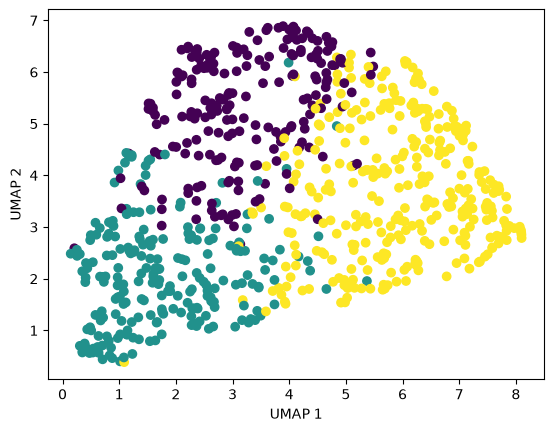

In [42]:
from umap import UMAP
import matplotlib.pyplot as plt

umap = UMAP(n_components=2, random_state=42)

X_umap = umap.fit_transform(df[features])

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

In [43]:
# 1. BMI category
df["BMI_Category"] = pd.cut(
    df["BMI"],
    bins=[-float("inf"), 18.5, 25, 30, float("inf")],
    labels=[0, 1, 2, 3]
).astype(float)

# 2. Age category
df["Age_Category"] = pd.cut(
    df["Age"],
    bins=[-float("inf"), 30, 40, float("inf")],
    labels=[0, 1, 2]
).astype(float)

# # 3. Glucose category
df["Glucose_Category"] = pd.cut(
    df["Glucose"],
    bins=[-float("inf"), 100, 126, float("inf")],
    labels=[0, 1, 2]
).astype(float)

# # 4. Blood pressure category
df["BP_Category"] = pd.cut(
    df["BloodPressure"],
    bins=[-float("inf"), 80, 90, float("inf")],
    labels=[0, 1, 2]
).astype(float)

# 5. BMI × Glucose
# df["BMI_Glucose"] = df["BMI"] * df["Glucose"]

# 6. Age × Glucose
# df["Age_Glucose"] = df["Age"] * df["Glucose"]

# 7. Age × BMI
# df["Age_BMI"] = df["Age"] * df["BMI"]

# 8. Insulin / Glucose ratio
df["Insulin_Glucose_Ratio"] = df["Insulin"] / df["Glucose"]

df = df.drop(columns=['BMI','Age', 'Glucose', 'BloodPressure'])

In [44]:
print(df.columns)

Index(['Pregnancies', 'SkinThickness', 'Insulin', 'DiabetesPedigreeFunction',
       'BMI_Category', 'Age_Category', 'Glucose_Category', 'BP_Category',
       'Insulin_Glucose_Ratio'],
      dtype='str')


In [45]:
# _____________________<( columns data type )>___________________
column_type = df.dtypes
print(f'columns types : {column_type}')

columns types : Pregnancies                 float64
SkinThickness               float64
Insulin                     float64
DiabetesPedigreeFunction    float64
BMI_Category                float64
Age_Category                float64
Glucose_Category            float64
BP_Category                 float64
Insulin_Glucose_Ratio       float64
dtype: object


In [46]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaled = scaler.fit_transform(df)

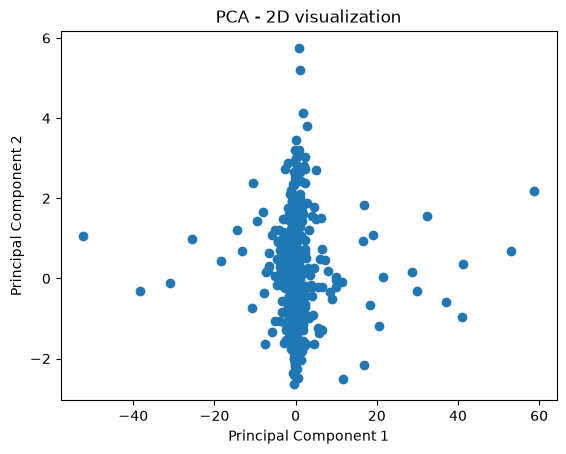

In [47]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

import matplotlib.pyplot as plt

plt.scatter(X_pca[:, 0], X_pca[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D visualization")

plt.show()

[0.8645222453433584, 0.8664118608682263, 0.7053115356729549, 0.4953217801281909, 0.49600161084835026]
5


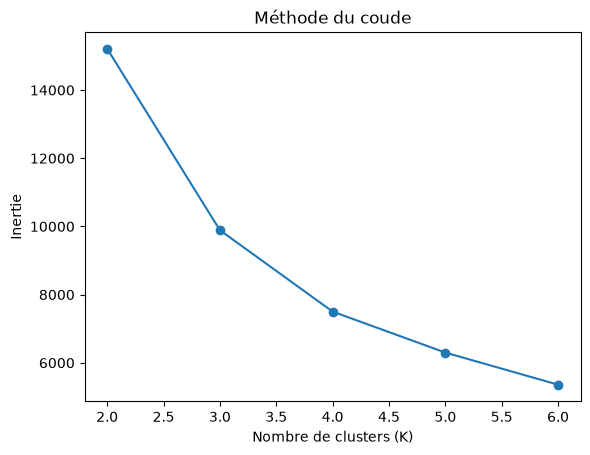

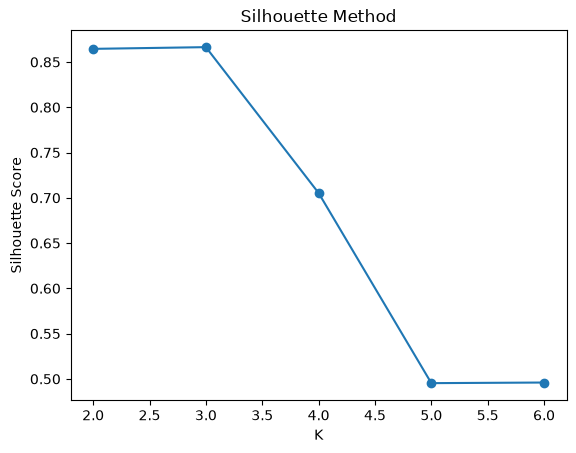

In [48]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


inertias = []
silhouette_scores = []


for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    # kmeans.fit(df[numeric_cols])
    labels = kmeans.fit_predict(df)
    
    inertias.append(kmeans.inertia_)
    score = silhouette_score(df, labels)
    silhouette_scores.append(score)

print(silhouette_scores)
print(len(silhouette_scores))


# elbow
plt.plot(range(2, 7), inertias, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.show()

# silouhaitte
plt.plot(range(2, 7), silhouette_scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")

plt.show()

c:\Users\ycode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


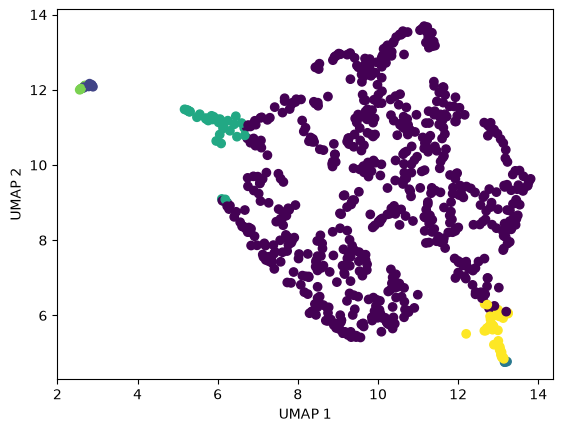

In [49]:
from umap import UMAP
import matplotlib.pyplot as plt

umap = UMAP(n_components=2, random_state=42)

X_umap = umap.fit_transform(df)

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

## ___<( Clustring )>___


In [50]:
# from sklearn.cluster import KMeans
# import pandas as pd

# # 1. Fit optimal K-Means model with K = 2
# kmeans = KMeans(n_clusters=2, random_state=42).fit(x_scaled)
# df['cluster'] = kmeans.labels_


# # Select your newly engineered columns
# features_to_inspect = [
#     'Glucose', 
#     'BMI', 
#     # 'Age', 
#     'Insulin',
#     'DiabetesPedigreeFunction',
#     # 'BloodPressure',
#     # 'Pregnancies'
# ]

# # 2. Inspect mean values to identify which cluster is High vs Low risk
# cluster_profile = df.groupby('cluster')[features_to_inspect].mean()
# print(cluster_profile.round(2))


# # 3. Map cluster IDs (0 and 1) to readable labels based on Step 2
# # (Swap values if cluster 0 turns out to have higher Glucose/BMI)
# risk_map = {
#     0: 'High Risk',
#     1: 'Low Risk'
# }

# df['risk_tier'] = df['cluster'].map(risk_map)

In [51]:
# import pandas as pd

# df.to_csv('../data/cleaned_data.csv')

In [52]:
# import pandas as pd

# df = pd.read_csv('../data/cleaned_data.csv')

In [53]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Countplot — combien d'observations par cluster
# plt.figure(figsize=(6, 4))
# sns.countplot(x='cluster', data=df, palette=['#2ecc71', '#e74c3c'])
# plt.title('Répartition des observations par cluster')
# plt.xlabel('Cluster')
# plt.ylabel("Nombre d'observations")

# # Ajouter les pourcentages sur les barres
# total = len(df)
# for p in plt.gca().patches:
#     pct = f"{100 * p.get_height() / total:.1f}%"
#     plt.gca().annotate(pct, (p.get_x() + p.get_width() / 2, p.get_height() + 3), ha='center')

# plt.tight_layout()
# plt.savefig('../figures/cluster_distribution.png')
# plt.show()


In [54]:
# print(df['cluster'].value_counts())
# # cluster
# # 1    399
# # 0    369

# # cluster
# # 1    421
# # 0    347